Rebuilding the QAOA module notebook in the git repo

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw as draw_graph
from itertools import product

from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from scipy.optimize import minimize

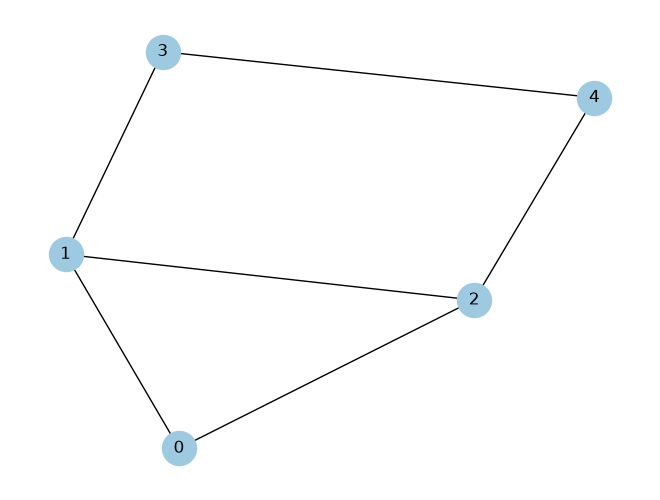

In [2]:
# Build a small 5-node graph
num_nodes = 5
edges = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 4), (3, 4)]

graph = rx.PyGraph()
graph.add_nodes_from(range(num_nodes))
graph.add_edges_from([(i, j, 1.0) for i, j in edges])  # weight 1 on every edge

draw_graph(graph, node_size=600, with_labels=True, node_color="#9ecae1")

In [3]:
def maxcut_cost_hamiltonian(num_nodes, edges):
    """Build the Max-Cut cost Hamiltonian sum_(i,j) 0.5 * Z_i Z_j."""
    terms = []
    for i, j in edges:
        pauli = ["I"] * num_nodes
        pauli[i] = "Z"
        pauli[j] = "Z"
        # Qiskit reads Pauli strings right-to-left (qubit 0 is the rightmost char)
        terms.append(("".join(reversed(pauli)), 0.5))
    return SparsePauliOp.from_list(terms)


cost_hamiltonian = maxcut_cost_hamiltonian(num_nodes, edges)
print("Cost Hamiltonian (one ZZ term per edge):")
print(cost_hamiltonian)

Cost Hamiltonian (one ZZ term per edge):
SparsePauliOp(['IIIZZ', 'IIZIZ', 'IIZZI', 'IZIZI', 'ZIZII', 'ZZIII'],
              coeffs=[0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j])


QAOA depth p = 1
Number of qubits: 5
Number of parameters: 2


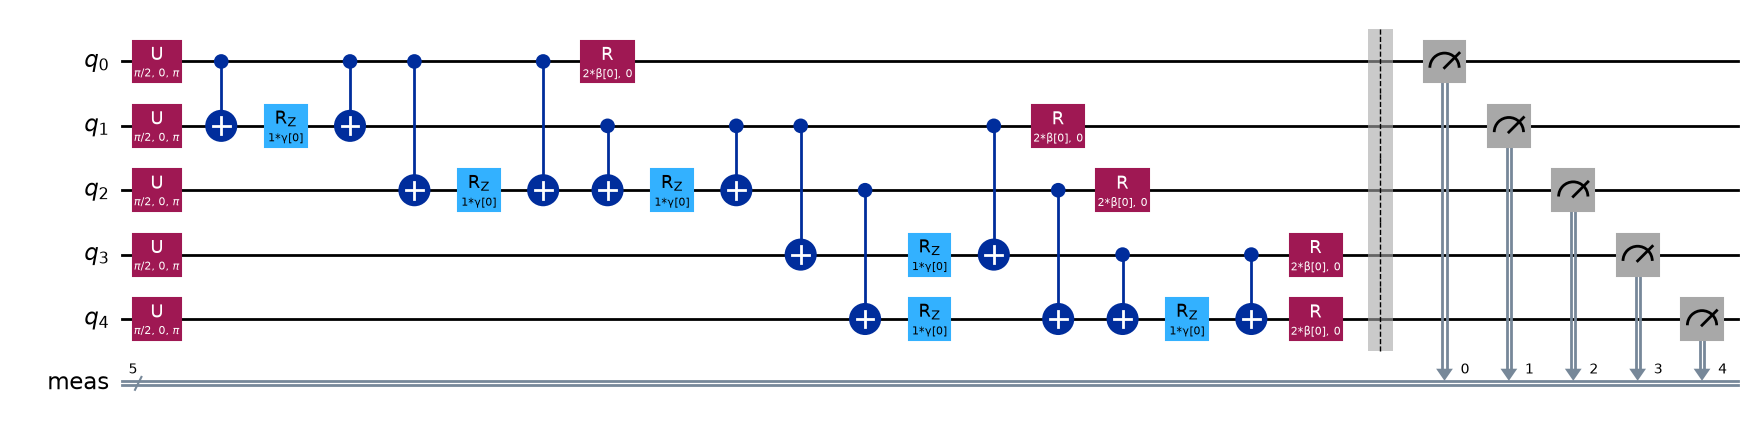

In [4]:
p = 1  # QAOA depth (number of layers)
ansatz = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=p)
ansatz.measure_all()

print(f"QAOA depth p = {p}")
print("Number of qubits:", ansatz.num_qubits)
print("Number of parameters:", ansatz.num_parameters)
ansatz.decompose(reps=3).draw("mpl", fold=-1)

In [5]:
estimator = StatevectorEstimator()

# Estimator needs the circuit without measurements
ansatz_no_meas = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=p)

objective_history = []

def cost_function(params):
    """Expected energy of the cost Hamiltonian for given QAOA angles."""
    pub = (ansatz_no_meas, cost_hamiltonian, params)
    energy = estimator.run([pub]).result()[0].data.evs
    energy = float(energy)
    objective_history.append(energy)
    return energy

# QAOA is sensitive to initialization: a single random start can stall in a poor local minimum.
# Try a few starting points and keep the best run.
rng = np.random.default_rng(42)
result, best_history = None, []
for _ in range(8):
    objective_history.clear()
    initial_params = rng.uniform(0, np.pi, ansatz_no_meas.num_parameters)
    trial = minimize(cost_function, initial_params, method="COBYLA",
                     options={"maxiter": 200})
    if result is None or trial.fun < result.fun:
        result, best_history = trial, list(objective_history)
objective_history = best_history  # convergence curve of the best run

print("Optimization finished.")
print("Optimal parameters:", np.round(result.x, 4))
print(f"Minimum expected energy: {result.fun:.4f}")

/home/sreeram/miniconda3/envs/qiskit_env/lib/python3.11/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/sreeram/miniconda3/envs/qiskit_env/lib/python3.11/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/home/sreeram/miniconda3/envs/qiskit_env/lib/python3.11/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Optimization finished.
Optimal parameters: [1.217  0.6491]
Minimum expected energy: -1.1101


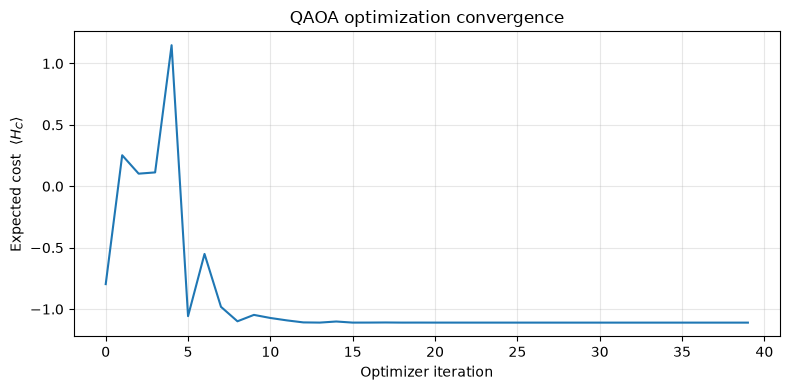

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(objective_history, color="#1f77b4")
plt.xlabel("Optimizer iteration")
plt.ylabel(r"Expected cost  $\langle H_C \rangle$")
plt.title("QAOA optimization convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
def cut_value(bitstring, edges):
    """Number of edges cut by a given assignment (bitstring)."""
    # bitstring[i] is the side (0 or 1) assigned to node i
    return sum(1 for i, j in edges if bitstring[i] != bitstring[j])


sampler = StatevectorSampler()
best = ansatz.assign_parameters(result.x)
samples = sampler.run([best], shots=4096).result()[0].data.meas.get_counts()

# Convert each measured key (a bit-string) into a per-node assignment.
# Qiskit bitstrings are little-endian: the rightmost char is qubit 0.
def key_to_assignment(key, num_nodes):
    bits = key.replace(" ", "")[::-1]  # reverse -> index 0 is node 0
    return [int(bits[i]) for i in range(num_nodes)]

scored = []
for key, count in samples.items():
    assignment = key_to_assignment(key, num_nodes)
    scored.append((assignment, count, cut_value(assignment, edges)))

# Sort by how often each bitstring appeared
scored.sort(key=lambda t: t[1], reverse=True)
print("Most sampled bitstrings (assignment, count, cut value):")
for assignment, count, cut in scored[:5]:
    print(f"  {assignment}   count={count:5d}   cut={cut}")

Most sampled bitstrings (assignment, count, cut value):
  [1, 1, 0, 0, 1]   count=  436   cut=5
  [1, 0, 1, 1, 0]   count=  429   cut=5
  [0, 1, 0, 0, 1]   count=  427   cut=5
  [0, 0, 1, 1, 0]   count=  419   cut=5
  [1, 0, 0, 1, 1]   count=  305   cut=4


Brute-force optimal cut : 5
QAOA best sampled cut   : 5
Approximation ratio     : 1.000


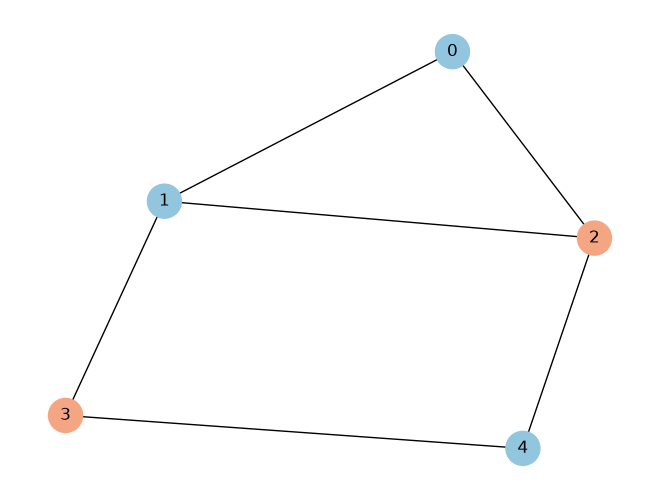

In [8]:
# Brute-force optimum
best_cut, best_assignments = 0, []
for bits in product([0, 1], repeat=num_nodes):
    c = cut_value(bits, edges)
    if c > best_cut:
        best_cut, best_assignments = c, [bits]
    elif c == best_cut:
        best_assignments.append(bits)

qaoa_best = max(scored, key=lambda t: t[2])
qaoa_cut = qaoa_best[2]
approx_ratio = qaoa_cut / best_cut

print(f"Brute-force optimal cut : {best_cut}")
print(f"QAOA best sampled cut   : {qaoa_cut}")
print(f"Approximation ratio     : {approx_ratio:.3f}")

# Visualize the QAOA partition
colors = ["#f4a582" if b == 0 else "#92c5de" for b in qaoa_best[0]]
draw_graph(graph, node_size=600, with_labels=True, node_color=colors)